# Generating handwritten digits with a variational autoencoder
**AI Foundations (Edward Hickman) · Udacity · Project 5 — Generative AI Applications**

Goal: learn a distribution of small digit images, then generate images without
feeding a real image into the encoder. This is **not digit classification**.
MNIST contains real human handwriting and is distinct from the prior Fashion-MNIST
clothing experiment. No external AI service or pretrained model is used.

The full model, loss, training and generation code are below. `EXPERIMENT_PLAN.md`
records choices before training. AI assistance is disclosed: Edward must review,
understand and personalize this work as required by his course policy.

## 1. Environment and reproducibility
Use the accompanying Python 3.11 CPU installation instructions and frozen
`requirements.txt`. Seeds and deterministic algorithms target repeatability on
this stack, not bitwise equality across all platforms (PyTorch contributors, n.d.-b).
The model is deliberately trained on CPU even if another device is available.

In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import struct
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display

ROOT = Path.cwd()
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED, SAMPLE_SEED = 20261119, 20261120
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "torch": torch.__version__,
            "device": str(DEVICE), "cuda_available": torch.cuda.is_available(),
            "threads": torch.get_num_threads()}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(versions)

{'python': '3.11.18',
 'numpy': '2.4.6',
 'pandas': '3.1.1',
 'torch': '2.15.0+cpu',
 'device': 'cpu',
 'cuda_available': False,
 'threads': 2}

## 2. Real dataset source, inspection and preparation
MNIST has 60,000 official training and 10,000 test images, 28×28 pixels,
with digit labels 0–9 (TensorFlow, n.d.). Labels are used **only** to inspect
coverage and choose one reconstruction example per digit; the VAE never receives
labels or uses a classification loss. Original files are included and checked
against published MD5 fingerprints. Missing files download from the CVDF mirror,
never from a replacement dataset.

The supplied source files remain unmodified. Scaled pixels are thresholded at
`>=0.5` to give binary observations appropriate for a Bernoulli decoder
(Kingma & Welling, 2013). This removes antialiasing and some handwriting detail;
Figure 1 shows the change. Data attribution and CC BY-SA 3.0 notice are in
`data/DATA_NOTICE.md`; the terms are documented by Keras (n.d.).

In [2]:
RESOURCES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}
manifest = []
for name, md5 in RESOURCES.items():
    url = "https://storage.googleapis.com/cvdf-datasets/mnist/" + name
    path = DATA / name
    if not path.exists():
        with urllib.request.urlopen(url, timeout=120) as response:
            path.write_bytes(response.read())
    raw = path.read_bytes()
    assert hashlib.md5(raw).hexdigest() == md5, f"Source fingerprint mismatch: {name}"
    manifest.append({"file": "data/" + name, "url": url, "bytes": len(raw),
                     "md5": md5, "sha256": hashlib.sha256(raw).hexdigest()})
(OUT / "dataset_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

def load_idx(name, images):
    raw = gzip.decompress((DATA / name).read_bytes())
    if images:
        magic, count, rows, columns = struct.unpack(">IIII", raw[:16])
        assert magic == 2051 and (rows, columns) == (28, 28)
        assert len(raw) == 16 + count * rows * columns
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, columns).copy()
    magic, count = struct.unpack(">II", raw[:8])
    assert magic == 2049 and len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

raw_train = load_idx("train-images-idx3-ubyte.gz", True)
raw_test = load_idx("t10k-images-idx3-ubyte.gz", True)
train_labels = load_idx("train-labels-idx1-ubyte.gz", False)
test_labels = load_idx("t10k-labels-idx1-ubyte.gz", False)
assert raw_train.shape == (60000, 28, 28) and raw_test.shape == (10000, 28, 28)
assert train_labels.shape == (60000,) and test_labels.shape == (10000,)
assert set(train_labels) == set(range(10)) and set(test_labels) == set(range(10))

permutation = np.random.default_rng(SEED).permutation(60000)
train_idx, val_idx = np.sort(permutation[5000:]), np.sort(permutation[:5000])
train_binary = (raw_train.astype(np.float32) / 255 >= 0.5).astype(np.float32)
test_binary = (raw_test.astype(np.float32) / 255 >= 0.5).astype(np.float32)
x_train = torch.from_numpy(train_binary[train_idx].reshape(-1, 784))
x_val = torch.from_numpy(train_binary[val_idx].reshape(-1, 784))
x_test = torch.from_numpy(test_binary.reshape(-1, 784))
assignments = pd.DataFrame({"official_index": np.arange(60000), "split": "training",
                            "digit": train_labels})
assignments.loc[val_idx, "split"] = "validation"
assignments.to_csv(OUT / "split_assignments.csv", index=False)

def pixel_hashes(images):
    return [hashlib.sha256(row.tobytes()).hexdigest() for row in images]

train_hashes = pixel_hashes(raw_train)
test_hashes = pixel_hashes(raw_test)
binary_hashes = pixel_hashes(train_binary.astype(np.uint8))
binary_test_hashes = pixel_hashes(test_binary.astype(np.uint8))
raw_training_hash_set = set(train_hashes)
binary_training_hash_set = {binary_hashes[j] for j in train_idx}
data_audit = {
    "official_training_shape": list(raw_train.shape),
    "official_test_shape": list(raw_test.shape),
    "training_count": len(x_train), "validation_count": len(x_val),
    "test_count": len(x_test), "threshold": 0.5,
    "training_index_sha256": hashlib.sha256(train_idx.astype("<i8").tobytes()).hexdigest(),
    "validation_index_sha256": hashlib.sha256(val_idx.astype("<i8").tobytes()).hexdigest(),
    "raw_training_repeats": len(train_hashes) - len(set(train_hashes)),
    "raw_test_repeats": len(test_hashes) - len(set(test_hashes)),
    "raw_test_matching_official_train": sum(h in raw_training_hash_set for h in test_hashes),
    "binarized_validation_matching_training":
        sum(binary_hashes[i] in binary_training_hash_set for i in val_idx),
    "binarized_test_matching_training":
        sum(h in binary_training_hash_set for h in binary_test_hashes),
    "original_dtype": str(raw_train.dtype), "model_dtype": str(x_train.dtype),
}
(OUT / "data_audit.json").write_text(json.dumps(data_audit, indent=2) + "\n")
display(data_audit)
counts = pd.DataFrame({
    "digit": range(10),
    "training": np.bincount(train_labels[train_idx], minlength=10),
    "validation": np.bincount(train_labels[val_idx], minlength=10),
    "test": np.bincount(test_labels, minlength=10)})
counts.to_csv(OUT / "digit_counts.csv", index=False)
display(counts)

{'official_training_shape': [60000, 28, 28],
 'official_test_shape': [10000, 28, 28],
 'training_count': 55000,
 'validation_count': 5000,
 'test_count': 10000,
 'threshold': 0.5,
 'training_index_sha256': 'f72ded1f3bcad512211afec7bc9c456a2c087ca5922bba91745485987ad7a5f3',
 'validation_index_sha256': '98eee46cf7cd691eb548d9e8b1008dc10e6cebbbecd74bbf6ff7b657ccbdf5cd',
 'raw_training_repeats': 0,
 'raw_test_repeats': 0,
 'raw_test_matching_official_train': 0,
 'binarized_validation_matching_training': 3,
 'binarized_test_matching_training': 8,
 'original_dtype': 'uint8',
 'model_dtype': 'torch.float32'}

,digit,training,validation,test
0,0,5410,513,980
1,1,6204,538,1135
2,2,5446,512,1032
3,3,5645,486,1010
4,4,5352,490,982
5,5,4982,439,892
6,6,5425,493,958
7,7,5761,504,1028
8,8,5335,516,974
9,9,5440,509,1009


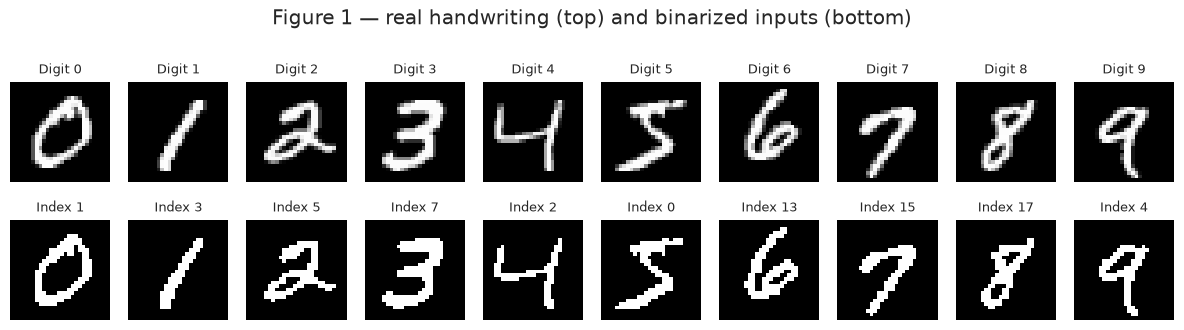

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3.6))
example_indices = [int(np.flatnonzero(train_labels == d)[0]) for d in range(10)]
for digit, index in enumerate(example_indices):
    for row, image in enumerate([raw_train[index] / 255, train_binary[index]]):
        axes[row, digit].imshow(image, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[row, digit].set_title(f"Digit {digit}" if row == 0 else f"Index {index}", fontsize=9)
        axes[row, digit].axis("off")
fig.suptitle("Figure 1 — real handwriting (top) and binarized inputs (bottom)")
fig.tight_layout()
fig.savefig(OUT / "figure_1_data_examples.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Complete VAE architecture and training objective
A VAE learns a probabilistic encoder and decoder and uses a latent prior to
generate content (Kingma & Welling, 2013). Here the encoder has 256 ReLU units,
then separate 16-dimensional `mu` and `logvar` heads. The decoder has 256 ReLU
units and 784 raw pixel logits. The Gaussian posterior is diagonal; its standard
deviation is `exp(0.5*logvar)`, **not** `exp(logvar)`. Reparameterization makes
sampled `z` differentiable with respect to encoder parameters.

For each image, loss = `sum(BCEWithLogits over 784 pixels) +
0.5*sum(mu² + exp(logvar) - 1 - logvar over 16 latent coordinates)`.
The batch mean is used for gradients. The KL coefficient is 1. The standard
normal prior and analytic KL follow the VAE derivation. BCE accepts logits
and [0,1] targets (PyTorch contributors, n.d.-a); sigmoid is **not** applied
before BCE. This small MLP and ten-epoch CPU budget make the implementation
inspectable, not state of the art. We do not claim these widths or settings
are optimal.

In [4]:
class DigitVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, 16)
        self.logvar = nn.Linear(256, 16)
        self.decoder = nn.Sequential(nn.Linear(16, 256), nn.ReLU(), nn.Linear(256, 784))

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden)

    def reparameterize(self, mu, logvar, generator):
        epsilon = torch.randn(mu.shape, generator=generator, device=mu.device)
        return mu + torch.exp(0.5 * logvar) * epsilon

    def forward(self, x, generator):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar, generator)
        return self.decoder(z), mu, logvar

def loss_components(logits, targets, mu, logvar):
    reconstruction = F.binary_cross_entropy_with_logits(logits, targets, reduction="none").sum(1)
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(1)
    return reconstruction, kl

torch.manual_seed(SEED)
model = DigitVAE().to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
config = {"seed": SEED, "sample_seed": SAMPLE_SEED, "latent_dimensions": 16,
          "hidden_units": 256, "batch_size": 256, "epochs": 10, "learning_rate": 0.001,
          "kl_coefficient": 1, "optimizer": "Adam", "betas": [0.9, 0.999],
          "eps": 1e-8, "weight_decay": 0, "foreach": False,
          "device": "cpu", "threads": 2, "parameter_count": parameter_count}
(OUT / "experiment_config.json").write_text(json.dumps(config, indent=2) + "\n")
print(model)
print("Trainable parameters:", parameter_count)

DigitVAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
  )
  (mu): Linear(in_features=256, out_features=16, bias=True)
  (logvar): Linear(in_features=256, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
  )
)
Trainable parameters: 415024


## 4. Train the model and display progress
Adam with learning rate 0.001 uses batches of 256 for ten full epochs.
Training randomness has its own generator; epoch order has separate fixed seeds.
Validation has the **same fixed posterior noise** at each epoch and is evaluated
without gradients. All images count equally, including the last partial batch.
Training metrics are online as weights change; validation uses end-of-epoch
weights. We retain epoch ten, not the best validation checkpoint. The official
test set does not guide training or hyperparameter selection.

In [5]:
@torch.inference_mode()
def evaluate(model, images, seed):
    model.eval()
    generator = torch.Generator().manual_seed(seed)
    totals = np.zeros(3, dtype=np.float64)
    records = []
    for start in range(0, len(images), 512):
        batch = images[start:start + 512]
        logits, mu, logvar = model(batch, generator)
        reconstruction, kl = loss_components(logits, batch, mu, logvar)
        mean_images = torch.sigmoid(model.decoder(mu))
        mse = (mean_images - batch).square().mean(1)
        totals += [reconstruction.double().sum().item(), kl.double().sum().item(),
                   mse.double().sum().item()]
        records.extend(zip(reconstruction.tolist(), kl.tolist(), mse.tolist()))
    metrics = dict(zip(["reconstruction_bce", "kl", "posterior_mean_mse"], totals / len(images)))
    metrics["total"] = metrics["reconstruction_bce"] + metrics["kl"]
    return metrics, pd.DataFrame(records, columns=["reconstruction_bce", "kl", "posterior_mean_mse"])

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, foreach=False)
train_generator = torch.Generator().manual_seed(SEED + 100)
history = []
started = time.perf_counter()
for epoch in range(1, 11):
    model.train()
    order = torch.randperm(len(x_train), generator=torch.Generator().manual_seed(SEED + epoch))
    sums = np.zeros(2, dtype=np.float64)
    for start in range(0, len(order), 256):
        batch = x_train[order[start:start + 256]]
        optimizer.zero_grad(set_to_none=True)
        logits, mu, logvar = model(batch, train_generator)
        reconstruction, kl = loss_components(logits, batch, mu, logvar)
        loss = (reconstruction + kl).mean()
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
        sums += [reconstruction.detach().double().sum().item(), kl.detach().double().sum().item()]
    validation, _ = evaluate(model, x_val, SEED + 200)
    rec, kl_mean = sums / len(x_train)
    row = {"epoch": epoch, "train_reconstruction_bce": rec, "train_kl": kl_mean,
           "train_total": rec + kl_mean, "validation_reconstruction_bce": validation["reconstruction_bce"],
           "validation_kl": validation["kl"], "validation_total": validation["total"]}
    history.append(row)
    print(f"Epoch {epoch:02d}: train total {rec + kl_mean:.3f}, "
          f"validation total {validation['total']:.3f}")
elapsed = time.perf_counter() - started
history = pd.DataFrame(history)
history.to_csv(OUT / "training_history.csv", index=False)
torch.save(model.state_dict(), OUT / "vae_state.pt")
(OUT / "training_seconds.json").write_text(json.dumps({"training_and_validation_seconds": elapsed}) + "\n")
display(history)

Epoch 01: train total 202.530, validation total 148.673


Epoch 02: train total 132.300, validation total 121.986


Epoch 03: train total 115.896, validation total 112.559


Epoch 04: train total 109.199, validation total 108.039


Epoch 05: train total 105.375, validation total 104.911


Epoch 06: train total 102.697, validation total 103.014


Epoch 07: train total 100.608, validation total 100.901


Epoch 08: train total 99.049, validation total 99.436


Epoch 09: train total 97.684, validation total 98.408


Epoch 10: train total 96.628, validation total 97.274


,epoch,train_reconstruction_bce,train_kl,train_total,validation_reconstruction_bce,validation_kl,validation_total
0,1,189.596111,12.933603,202.529714,131.715963,16.957368,148.673332
1,2,112.650362,19.649934,132.300296,100.108002,21.877942,121.985944
2,3,93.540645,22.355727,115.896372,89.529404,23.029443,112.558847
3,4,86.041036,23.158038,109.199074,84.201057,23.838311,108.039369
4,5,81.678867,23.696474,105.375341,81.024437,23.886472,104.910909
5,6,78.619148,24.078341,102.697489,78.345474,24.668886,103.014359
6,7,76.213337,24.394676,100.608013,76.497897,24.403156,100.901053
7,8,74.402285,24.647053,99.049338,74.857503,24.578884,99.436387
8,9,72.840191,24.843654,97.683845,73.120753,25.287467,98.408220
9,10,71.543745,25.084222,96.627966,72.311015,24.963261,97.274277


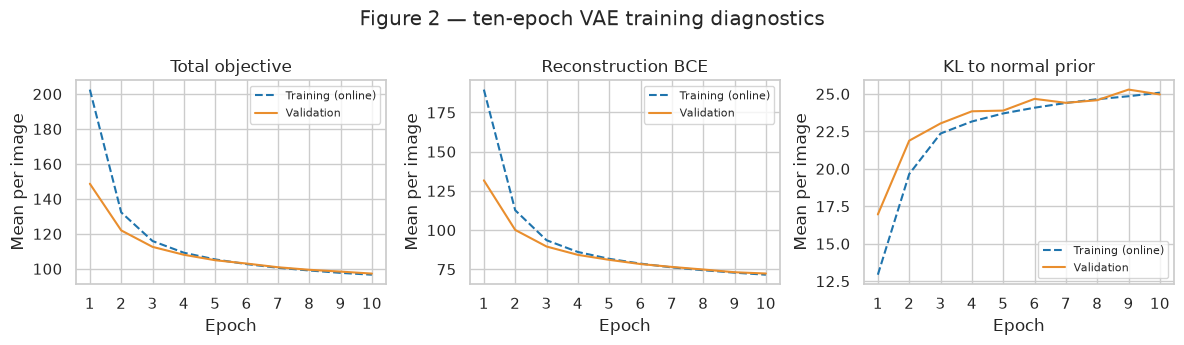

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, component, label in zip(axes, ["total", "reconstruction_bce", "kl"],
                                ["Total objective", "Reconstruction BCE", "KL to normal prior"]):
    ax.plot(history.epoch, history["train_" + component], "--", color="#1F74AD", label="Training (online)")
    ax.plot(history.epoch, history["validation_" + component], color="#E98E2E", label="Validation")
    ax.set(xlabel="Epoch", ylabel="Mean per image", title=label, xticks=range(1, 11))
    ax.legend(fontsize=8)
fig.suptitle("Figure 2 — ten-epoch VAE training diagnostics")
fig.tight_layout()
fig.savefig(OUT / "figure_2_training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Generate from the prior — not reconstructions
Draw all 64 latent vectors once from `N(0,I)` using seed 20261120; no images
or labels enter this generation step. Figure 3 shows sigmoid decoder outputs,
the **conditional mean pixel probabilities**, not actual binary pixel draws.
Figure 4 samples each pixel from its Bernoulli distribution with a separate
fixed seed. These are literal binary samples from the modeled likelihood.
The same latent vectors underlie both views. All 64 are retained in order,
without selection or regeneration to hide failures.

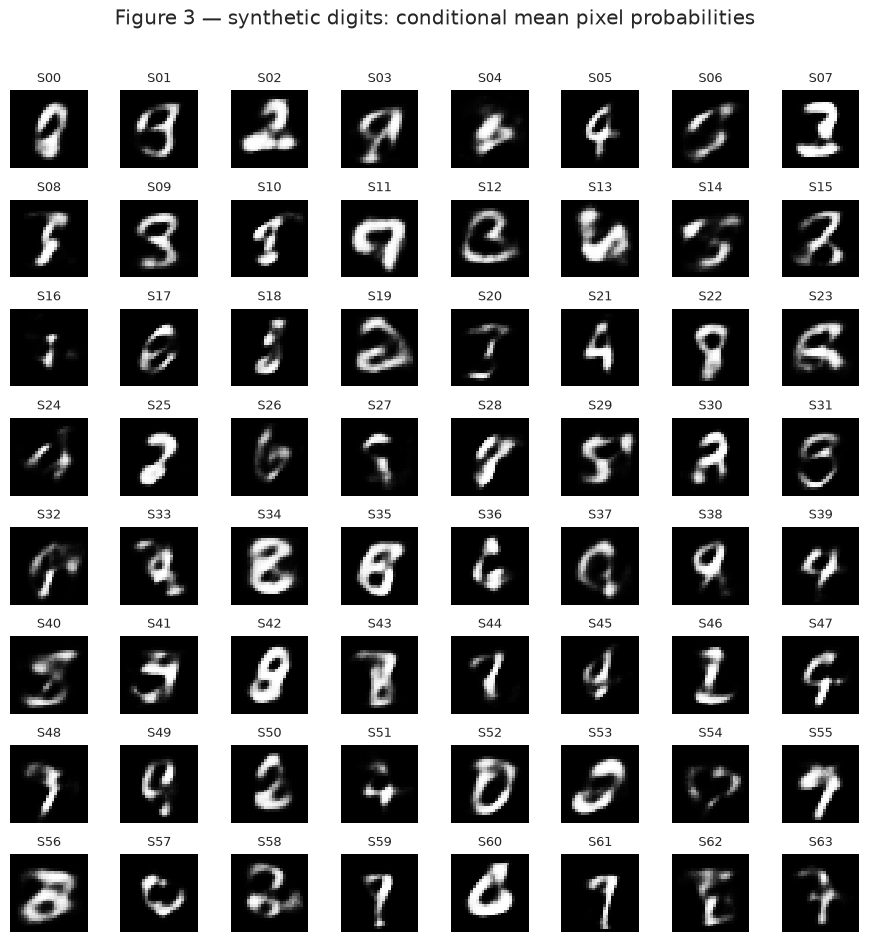

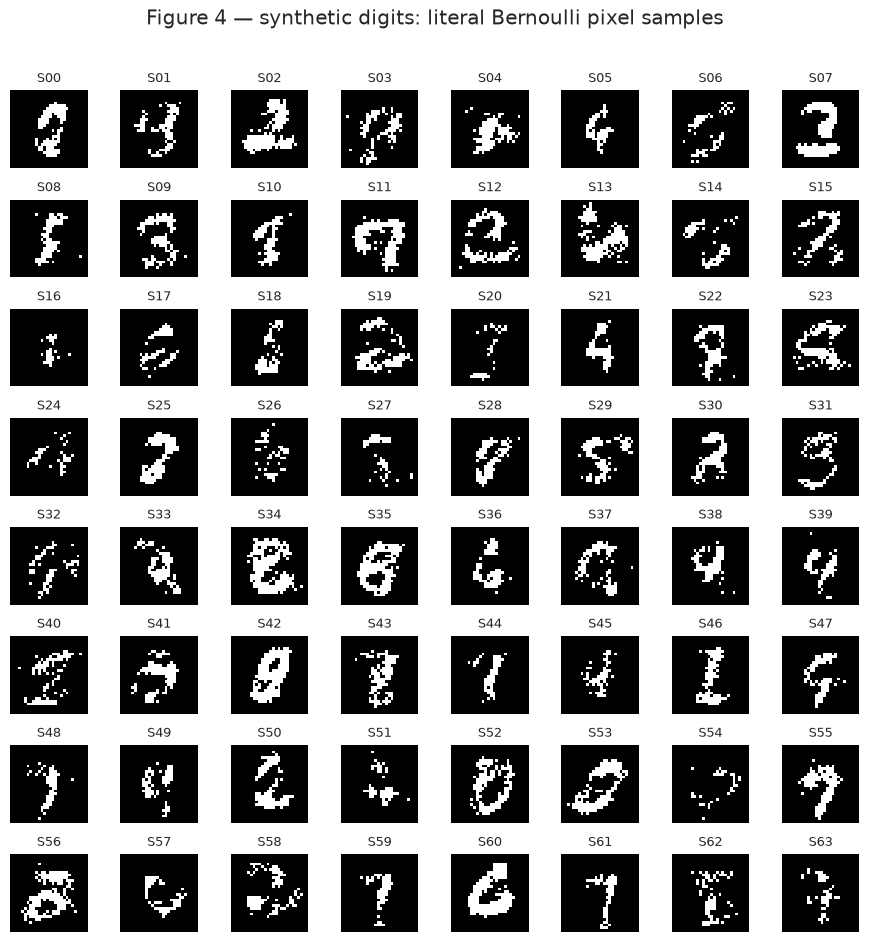

In [7]:
model.eval()
with torch.inference_mode():
    z = torch.randn(64, 16, generator=torch.Generator().manual_seed(SAMPLE_SEED))
    generated = torch.sigmoid(model.decoder(z)).reshape(64, 28, 28)
    binary_samples = torch.bernoulli(generated, generator=torch.Generator().manual_seed(SAMPLE_SEED + 1))
np.save(OUT / "prior_latents.npy", z.numpy())
np.save(OUT / "generated_means.npy", generated.numpy())
np.save(OUT / "generated_binary_samples.npy", binary_samples.numpy())
for number, images, title, filename in [
    (3, generated, "conditional mean pixel probabilities", "figure_3_generated_means.png"),
    (4, binary_samples, "literal Bernoulli pixel samples", "figure_4_binary_samples.png")]:
    fig, axes = plt.subplots(8, 8, figsize=(9, 9.6))
    for index, ax in enumerate(axes.flat):
        ax.imshow(images[index], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"S{index:02d}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Figure {number} — synthetic digits: {title}")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(OUT / filename, dpi=160, bbox_inches="tight")
    plt.show()

## 6. Held-out reconstruction and limited similarity diagnostics
We report reconstruction BCE plus KL from one fixed posterior sample for each
test image, alongside posterior-mean pixel MSE. The total is a Monte Carlo
negative-ELBO estimate per image, **not exact negative log-likelihood**.
It measures the reconstruction/regularization objective, not whether generated
digits are legible or cover all styles (Theis et al., 2016).

Figure 5 pairs binarized originals and posterior-mean reconstructions of the
first official test image for each digit 0–9. These are different from prior
generations: reconstructions encode actual images. Figure 6 compares the first
eight prior means with their closest training images across **all 55,000**
training inputs. RMSE is normalized to [0,1] pixels. Similarity is descriptive,
not an identity, privacy, legal-ownership or absence-of-memorization test.

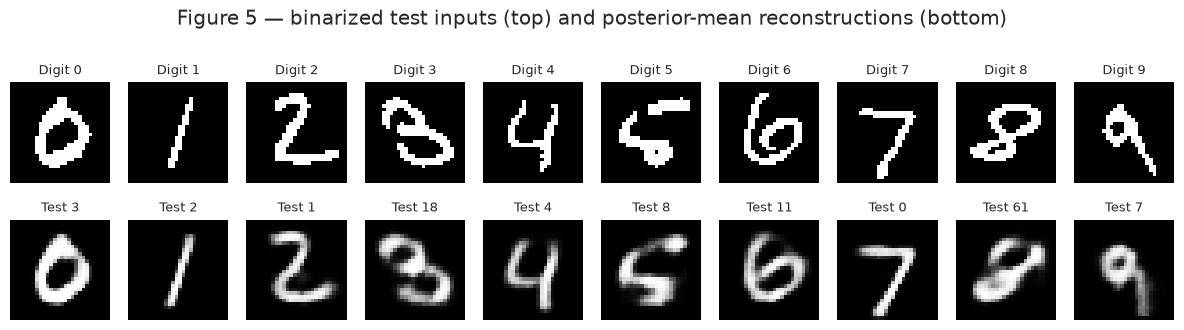

{'reconstruction_bce': np.float64(70.34817633857728),
 'kl': np.float64(25.002267742538454),
 'posterior_mean_mse': np.float64(0.02414663647877751),
 'total': np.float64(95.35044408111573)}

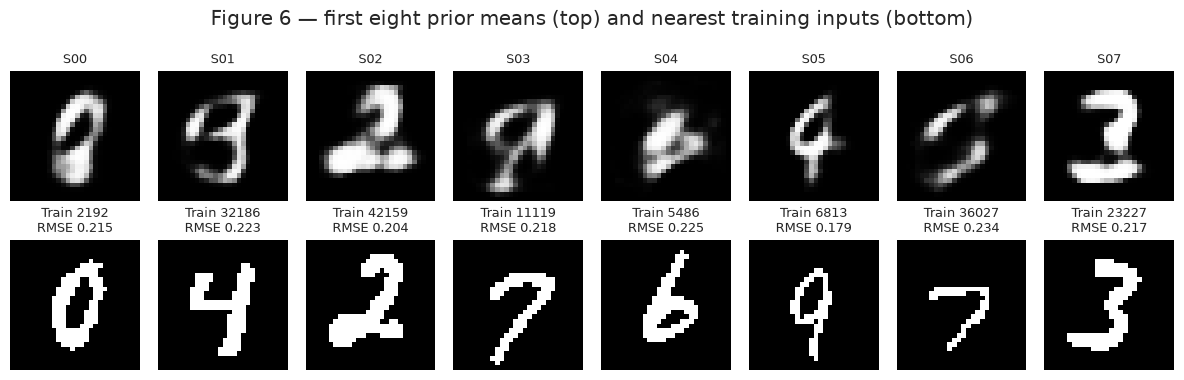

,sample_id,training_position,official_training_index,pixel_rmse
0,S00,2008,2192,0.215229
1,S01,29441,32186,0.222552
2,S02,38586,42159,0.204114
3,S03,10193,11119,0.218374
4,S04,5027,5486,0.224592
5,S05,6249,6813,0.178764
6,S06,32959,36027,0.233549
7,S07,21258,23227,0.217214


{'task': 'unconditional MNIST digit image generation',
 'parameter_count': 415024,
 'train_count': 55000,
 'validation_count': 5000,
 'test_count': 10000,
 'first_validation_total': 148.6733316418171,
 'final_validation_total': 97.27427651557923,
 'test': {'reconstruction_bce': np.float64(70.34817633857728),
  'kl': np.float64(25.002267742538454),
  'posterior_mean_mse': np.float64(0.02414663647877751),
  'total': np.float64(95.35044408111573)},
 'sample_count': 64,
 'nearest_rmse_min': 0.13600508868694305,
 'nearest_rmse_median': 0.20718252658843994,
 'nearest_rmse_max': 0.2622978091239929,
 'unique_quantized_generated_means': 64,
 'reconstruction_test_indices': [3, 2, 1, 18, 4, 8, 11, 0, 61, 7]}

In [8]:
test_metrics, test_records = evaluate(model, x_test, SEED + 300)
test_records.insert(0, "official_test_index", np.arange(10000))
test_records.insert(1, "digit", test_labels)
test_records.to_csv(OUT / "test_reconstruction_metrics.csv", index=False)
reconstruction_indices = [int(np.flatnonzero(test_labels == d)[0]) for d in range(10)]
with torch.inference_mode():
    mu, _ = model.encode(x_test[reconstruction_indices])
    reconstructed = torch.sigmoid(model.decoder(mu)).reshape(10, 28, 28)
np.save(OUT / "reconstructions.npy", reconstructed.numpy())
fig, axes = plt.subplots(2, 10, figsize=(12, 3.6))
for digit, index in enumerate(reconstruction_indices):
    for row, image in enumerate([test_binary[index], reconstructed[digit]]):
        axes[row, digit].imshow(image, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[row, digit].set_title(f"Digit {digit}" if row == 0 else f"Test {index}", fontsize=9)
        axes[row, digit].axis("off")
fig.suptitle("Figure 5 — binarized test inputs (top) and posterior-mean reconstructions (bottom)")
fig.tight_layout()
fig.savefig(OUT / "figure_5_reconstructions.png", dpi=180, bbox_inches="tight")
plt.show()
display(test_metrics)

with torch.inference_mode():
    best_distance = torch.full((64,), float("inf"))
    best_position = torch.zeros(64, dtype=torch.long)
    flat_generated = generated.reshape(64, 784)
    for start in range(0, len(x_train), 2048):
        distances = torch.cdist(flat_generated, x_train[start:start + 2048],
                               compute_mode="use_mm_for_euclid_dist")
        values, positions = distances.min(1)
        better = values < best_distance
        best_distance[better] = values[better]
        best_position[better] = positions[better] + start
    nearest_rmse = (flat_generated - x_train[best_position]).square().mean(1).sqrt()
nearest = pd.DataFrame({"sample_id": [f"S{i:02d}" for i in range(64)],
                        "training_position": best_position.numpy(),
                        "official_training_index": train_idx[best_position.numpy()],
                        "pixel_rmse": nearest_rmse.numpy()})
nearest.to_csv(OUT / "nearest_training_images.csv", index=False)
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for index in range(8):
    images = [generated[index], x_train[best_position[index]].reshape(28, 28)]
    titles = [f"S{index:02d}", f"Train {nearest.official_training_index.iloc[index]}\nRMSE {nearest.pixel_rmse.iloc[index]:.3f}"]
    for row in range(2):
        axes[row, index].imshow(images[row], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[row, index].set_title(titles[row], fontsize=9)
        axes[row, index].axis("off")
fig.suptitle("Figure 6 — first eight prior means (top) and nearest training inputs (bottom)")
fig.tight_layout()
fig.savefig(OUT / "figure_6_nearest_examples.png", dpi=180, bbox_inches="tight")
plt.show()
display(nearest.head(8))
summary = {"task": "unconditional MNIST digit image generation", "parameter_count": parameter_count,
           "train_count": len(x_train), "validation_count": len(x_val), "test_count": len(x_test),
           "first_validation_total": float(history.validation_total.iloc[0]),
           "final_validation_total": float(history.validation_total.iloc[-1]),
           "test": test_metrics, "sample_count": 64,
           "nearest_rmse_min": float(nearest.pixel_rmse.min()),
           "nearest_rmse_median": float(nearest.pixel_rmse.median()),
           "nearest_rmse_max": float(nearest.pixel_rmse.max()),
           "unique_quantized_generated_means": len(set(pixel_hashes(
               np.rint(generated.numpy() * 255).astype(np.uint8)))),
           "reconstruction_test_indices": reconstruction_indices}
(OUT / "experiment_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
display(summary)

## Qualitative evaluation of our actual outputs

**Strengths.** Figure 3 shows several recognizable digit-like shapes: S00 has an elongated closed loop resembling a 0, S02 has a curved upper stroke and broad horizontal base resembling a 2, and S42 has two joined loops resembling an 8. S00 and S42 also illustrate different loop structure and stroke thickness. These are visual interpretations of unlabeled generations, not assigned ground-truth labels or a measured success rate.

**Concrete failures.** S04 is a blurred, merged shape that is difficult to identify confidently. S06 has disconnected curved strokes, and S16 is a faint short mark rather than a clearly legible digit. S51 and S54 contain fragmented or incomplete shapes. The complete 64-image grid is shown, not a selection of attractive results. These examples show that lower training loss does not guarantee usable handwriting.

**Mean images versus literal samples.** S02 and S42 retain recognizable structure in Figure 4, but S01 and S06 become visibly speckled and broken when pixels are sampled. The grayscale display in Figure 3 represents decoder probabilities; it can look cleaner than the binary images actually drawn from the likelihood. Showing both avoids presenting the smoother view as the only outcome.

**Reconstruction is a separate task.** In Figure 5, test index 0 retains the strong 7-shaped outline and index 3 retains a closed loop. At test index 61, the two-loop 8 is smoother and less distinctly separated in the reconstruction. The source has been encoded for these examples, unlike the unconditional prior generations.

**Similarity and quantitative limits.** Figure 6 pairs S00 with training index 2192 (pixel RMSE 0.215), S01 with index 32186 (0.223), and S02 with index 42159 (0.204). The nearest input for S01 looks more like a 4 even though the generated mean looks more like a 3, illustrating that pixel similarity does not guarantee semantic agreement. Across all 64 means, nearest-training RMSE ranges from 0.136 to 0.262, with median 0.207; all 64 quantized mean images differ from each other. Neither observation proves originality, privacy, full digit coverage or the absence of memorization. Final test reconstruction BCE is 70.348 per image and KL is 25.002, yielding total 95.350; posterior-mean pixel MSE is 0.02415. These describe the reconstruction objective, not generation accuracy.

**Training and scope.** Validation total declined from 148.673 to 97.274 across the fixed ten epochs, while the KL term increased as reconstruction improved. No non-finite loss or training crash occurred; the remaining challenges are blurry means, noisy pixel draws and incomplete shapes rather than an invented convergence failure. Three validation images become pixel-identical to training images after binarization, although the original grayscale images do not match exactly. This limits independence of the processed validation data and is disclosed rather than hidden. Writer identities are absent, so writer-level independence and demographic representation cannot be established.

Eight test images also become pixel-identical to training inputs after binarization, representing 0.08% of the official test set; three validation images represent 0.06% of validation. Original grayscale images have no exact cross-set matches. Thresholding causes the collisions, and all planned official records remain included. These counts do not address writer identity or near duplicates.

## 7. Ethics, intended use and limitations
This is an educational generation demonstration, not an authenticity system.
Publish samples as **synthetic**, not as genuine handwriting, signed documents,
financial records or evidence. The source represents a restricted collection
of digit handwriting, not every person's writing style; writer demographics
and writer IDs are not provided in these IDX files. No demographic fairness
claim can be assessed from our labels. Dataset provenance and intended-use
documentation help expose such limits (Gebru et al., 2021).

The unconditional model cannot request a specific digit, generate meaningful
numbers or text, or authenticate a writer. Binarization removes details;
probability images can appear smoother than literal pixel draws. The 64-sample
grid and nearest-neighbor RMSE do not rule out memorization, prove originality
or settle copyright. Preserve source attribution and applicable license terms,
do not claim ownership of a real writer's style, and do not quietly substitute
these images for real examples in another dataset. Generated training data
would need separate diversity and downstream validation. No claim of real-world
recognition improvement, medical benefit, security or privacy is made.

One seed, one architecture and ten epochs limit conclusions. Realistic next
steps are a preplanned convolutional VAE comparison, longer-budget runs across
several seeds, explicit class-coverage review and multiple human raters.
These are proposals, not experiments already run. If extending to new private
handwriting, obtain permission and assess data protection before collection.

## References
Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H.,
& Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12),
86–92. https://doi.org/10.1145/3458723

Keras. (n.d.). *MNIST digits classification dataset*. https://keras.io/api/datasets/mnist/

Kingma, D. P., & Welling, M. (2013). *Auto-encoding variational Bayes* [Preprint].
arXiv. https://doi.org/10.48550/arXiv.1312.6114

PyTorch contributors. (n.d.-a). *torch.nn.functional.binary_cross_entropy_with_logits*.
PyTorch 2.15 documentation.
https://docs.pytorch.org/docs/2.15/generated/torch.nn.functional.binary_cross_entropy_with_logits.html

PyTorch contributors. (n.d.-b). *Reproducibility*. PyTorch 2.15 documentation.
https://docs.pytorch.org/docs/2.15/notes/randomness.html

TensorFlow. (n.d.). *mnist*. TensorFlow Datasets. https://www.tensorflow.org/datasets/catalog/mnist

Theis, L., van den Oord, A., & Bethge, M. (2016). *A note on the evaluation of generative
models* [Preprint]. arXiv. https://doi.org/10.48550/arXiv.1511.01844

## Notebook summary

This project trained an unconditional PyTorch variational autoencoder to generate small digit images from real, binarized MNIST handwriting. The fixed ten-epoch run lowered validation loss from 148.67 to 97.27 per image without changing the planned training settings. The fixed 64-image grid contains recognizable looped and curved digits alongside blurred S04 and disconnected S06 outputs. Literal Bernoulli pixel samples are noisier than the decoder means, and reconstructions can smooth away details. The limited handwriting source, single seed and small visual sample do not establish broad style coverage, privacy, originality or suitability for real records.